# Projeto - Previsão de Intenção de Compra de Clientes em Loja Web

**Descrição do Projeto**

Neste projeto, o objetivo é criar um sistema inteligente para antecipar a intenção de compra dos clientes em um site de e-commerce. Prevendo quais clientes têm maior probabilidade de realizar compras online, com base em suas características e comportamentos passados. Essa capacidade de prever a intenção de compra não só aprimorará a experiência do cliente, mas também permitirá que a empresa direcione seus esforços de marketing de forma mais eficaz.

**Objetivo**

Desenvolver um modelo preditivo capaz de analisar os padrões de comportamento dos clientes e identificar sinais que indicam a propensão deles para realizar compras no site da empresa. Para isso, vamos usar uma base de dados que contém informações detalhadas sobre os clientes, incluindo:

Dados demográficos (idade, renda, etc.)

Informações sobre compras anteriores

**Legenda dos dados:**

Year_Birth: Ano de nascimento do cliente

Education: Nível de escolaridade do cliente

Marital_Status: Estado civil do cliente

Income: Renda anual da família do cliente

Kidhome: Número de crianças na casa do cliente

Recency: Número de dias desde a última compra do cliente

Complain: 1 se o cliente reclamou nos últimos 2 anos, 0 caso contrário

MntWines: Valor gasto em vinhos nos últimos 2 anos

MntFruits: Valor gasto em frutas nos últimos 2 anos

MntMeatProducts: Valor gasto em carnes nos últimos 2 anos

MntFishProducts: Valor gasto em peixes nos últimos 2 anos

MntSweetProducts: Valor gasto em doces nos últimos 2 anos

MntGoldProds: Valor gasto em produtos de ouro nos últimos 2 anos

<!-- NumDealsPurchases: Número de compras feitas com desconto -->

NumStorePurchases: Número de compras feitas diretamente nas lojas

NumWebVisitsMonth: Número de visitas ao site da empresa no último mês

**WebPurchases (Target):** Fez compra (1) ou não (0) pelo site da empresa

# ETAPA 1:

**Preparação dos Dados**

**Exploração e Limpeza:** Analisar e limpar os dados para garantir que estejam prontos para a modelagem.

**Análise:** Construa uma storytelling com gráficos, analisando e retirando insights das informações.

In [ ]:
# Manipulação dos Dados
import pandas as pd
import numpy as np

# Visualização dos Gráficos
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

# Tratamento dos Dados
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Melhoria de Hiperparâmetros
from sklearn.model_selection import (
            train_test_split,
            cross_val_score, 
            GridSearchCV, 
            StratifiedKFold,
            RandomizedSearchCV
)
# Métricas de Avaliação
from sklearn.metrics import (
            classification_report, 
            confusion_matrix, roc_curve, 
            roc_auc_score
)
from scipy.stats import randint

In [33]:
df = pd.read_csv('marketing_campaign.csv', delimiter=';')

In [34]:
df.head()

,Year_Birth,Education,Marital_Status,Income,Kidhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumStorePurchases,NumWebVisitsMonth,Complain,WebPurchases
0,1957,Graduation,Single,58138.0,0,58,635,88,546,172,88,88,4,7,0,1
1,1954,Graduation,Single,46344.0,1,38,11,1,6,2,1,6,2,5,0,0
2,1965,Graduation,Together,71613.0,0,26,426,49,127,111,21,42,10,4,0,1
3,1984,Graduation,Together,26646.0,1,26,11,4,20,10,3,5,4,6,0,0
4,1981,PhD,Married,58293.0,1,94,173,43,118,46,27,15,6,5,0,1


### Limpeza dos Dados:

In [35]:
df.dtypes

Year_Birth             int64
Education                str
Marital_Status           str
Income               float64
Kidhome                int64
Recency                int64
MntWines               int64
MntFruits              int64
MntMeatProducts        int64
MntFishProducts        int64
MntSweetProducts       int64
MntGoldProds           int64
NumStorePurchases      int64
NumWebVisitsMonth      int64
Complain               int64
WebPurchases           int64
dtype: object

In [36]:
df.isnull().sum()

Year_Birth            0
Education             0
Marital_Status        0
Income               24
Kidhome               0
Recency               0
MntWines              0
MntFruits             0
MntMeatProducts       0
MntFishProducts       0
MntSweetProducts      0
MntGoldProds          0
NumStorePurchases     0
NumWebVisitsMonth     0
Complain              0
WebPurchases          0
dtype: int64

In [37]:
mediana = df['Income'].median()
df['Income'] = df['Income'].fillna(mediana)

Clientes sem registros de `Income` (nulo), foram substituidos pela mediana.

In [38]:
df.describe()

,Year_Birth,Income,Kidhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumStorePurchases,NumWebVisitsMonth,Complain,WebPurchases
count,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,1968.805804,52237.975446,0.444196,49.109375,303.935714,26.302232,166.950000,37.525446,27.062946,44.021875,5.790179,5.316518,0.009375,0.503571
std,11.984069,25037.955891,0.538398,28.962453,336.597393,39.773434,225.715373,54.628979,41.280498,52.167439,3.250958,2.426645,0.096391,0.500099
min,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1959.000000,35538.750000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,1.000000,9.000000,3.000000,3.000000,0.000000,0.000000
50%,1970.000000,51381.500000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,8.000000,24.000000,5.000000,6.000000,0.000000,1.000000
75%,1977.000000,68289.750000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,33.000000,56.000000,8.000000,7.000000,0.000000,1.000000
max,1996.000000,666666.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,362.000000,13.000000,20.000000,1.000000,1.000000


### Verificando Outliers:

In [7]:
fig = px.box(df, y='Income', title='BoxPlot de Income')
fig.show()

In [39]:
Q1 = df['Income'].quantile(0.25)
Q3 = df['Income'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(limite_inferior, limite_superior)

-13587.75 117416.25


In [40]:
# Identifica valores fora dos limites do IQR
outliers = (
    (df['Income'] < limite_inferior) |
    (df['Income'] > limite_superior))

# Calcula a mediana sem os outliers identificados
mediana_sem_outliers = df.loc[~outliers, 'Income'].median()

# Substitui os outliers pela mediana
df.loc[outliers, 'Income'] = mediana_sem_outliers

In [11]:
fig = px.box(df, y='Income', title='BoxPlot de Income')
fig.show()

Utilizei o gráfico BoxPlot e o método IQR (Intervalo Interquartil) para identificar e tratar os outliers, pois a variável `Income` apresentava pontos distantes dos demais valores. Esse método utiliza os quartis Q1 e Q3 para calcular o intervalo interquartil e estabelecer limites para identificar possíveis valores atípicos. Durante o tratamento, os valores que ultrapassavam esses limites foram tratados com base na mediana dos dados considerados dentro do intervalo.

In [12]:
fig = px.box(df, y='Year_Birth', title='BoxPlot de Year_Birth')
fig.show()

In [41]:
Q1 = df['Year_Birth'].quantile(0.25)
Q3 = df['Year_Birth'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(limite_inferior, limite_superior)

1932.0 2004.0


In [42]:
# Identifica valores fora dos limites do IQR
outliers = (
    (df['Year_Birth'] < limite_inferior) |
    (df['Year_Birth'] > limite_superior))

# Calcula a mediana sem os outliers identificados
mediana_sem_outliers = df.loc[~outliers, 'Year_Birth'].median()

# Substitui os outliers pela mediana
df.loc[outliers, 'Year_Birth'] = mediana_sem_outliers

In [12]:
fig = px.box(df, y='Year_Birth', title='BoxPlot de Year_Birth')
fig.show()

Utilizei novamente o gráfico BoxPlot e o método IQR (Intervalo Interquartil) para identificar e tratar os outliers, pois a variável `Year_Birth` apresentava pontos muito abaixo dos demais valores. Durante o tratamento, os valores abaixo do limite inferior foram tratados com base na mediana dos dados considerados dentro do intervalo. Ou seja, clientes com `Year_Birth` muito abaixo do esperado pela base (pessoas com mais de 100 anos, de acordo com o `Year_Birth` registrado), foram substituídos pela mediana.

### Análise Univariada nas variáveis categóricas:

In [ ]:
fig = px.bar(df["Education"].value_counts().reset_index(), 
            x="Education", y="count", title="Quantidade por Education")

fig.show()

In [17]:
contagem = df['Education'].value_counts()
(contagem / contagem.sum() * 100).round(2)

Education
Graduation    50.31
PhD           21.70
Master        16.52
2n Cycle       9.06
Basic          2.41
Name: count, dtype: float64

Observa-se no gráfico a concentração de indivíduos na categoria `Graduation` (50.31%), que corresponde a aproximadamente metade da base de dados. Seguida da categoria `PhD` (21.70%), à segunda categoria mais frequente e `Master` (16.52%) sendo a terceira categoria mais presente. Já as categorias `2n Cycle` (9.06%) e `Basic` (2.41%), apresentam participação reduzida, indicando que indivíduos com esses níveis de escolaridade são pouco representativos na base de dados.

In [7]:
fig = px.bar(df["Marital_Status"].value_counts().reset_index(), 
            x="Marital_Status", y="count", title="Quantidade por Marital_Status")

fig.show()

In [8]:
contagem = df['Marital_Status'].value_counts()
(contagem / contagem.sum() * 100).round(2)

Marital_Status
Married     38.57
Together    25.89
Single      21.43
Divorced    10.36
Widow        3.44
Alone        0.13
Absurd       0.09
YOLO         0.09
Name: count, dtype: float64

Observa-se no gráfico que as categorias `Married` (38.57%), `Together` (25.89%) e `Single` (21.43%) concentram a maior parte dos registros, enquanto `Divorced` (10.36%) e `Widow` (3.44%) apresentam frequências menores. As categorias `Alone` (0.13%), `Absurd` (0.09%) e `YOLO` (0.09%) possuem participação praticamente insignificante na base de dados, o que pode indicar inconsistências ou possíveis erros de preenchimento e classificação.
Dessa forma, em uma etapa posterior do tratamento dos dados, as categorias `Alone`, `Absurd` e `YOLO` serão removidas.

### Análise Biviariada:

**Respondendo as seguintes perguntas com gráficos seguidos de insights:**

- Quanto maior o nível de `Education` maior o `Income`?

- O `Marital_Status` do cliente influência o valor de `Income`?

- Pessoas com maior valor `Income` tendem a fazer compras online `WebPurchases`?

- O nível de `Education` do cliente indica que ele está propicio a fazer compras online `WebPurchases`?

- Algum estado de `Marital_Status` específico indica que o cliente está propicio a fazer compras online `WebPurchases`?

- O alto valor em compras de produtos `MntGoldProds` é um indicar de que o cliente está propicio a fazer compras online `WebPurchases`?

- O alto número de `NumWebVisitsMonth` indica que o cliente fez compras online `WebPurchases`? 

- Clientes que já tenham comprado na loja física `NumStorePurchases` tendem a comprar online `WebPurchases`?

- Clientes que fazem compras online `WebPurchases` consomem bebidas alcoólicas `MntWines`?

In [ ]:
mediana = df.groupby('Education')['Income'].median().reset_index()

fig = px.bar(mediana, x='Education', y='Income',
            title='Mediana Income com Education')
fig.show()

Observa-se no gráfico que pessoas com `Education` em `PhD`, `Master`, e `Graduation` tem maior número de `Income` anual. Ou seja, quanto maior o desenvolvimento em `Education`, maior o valor de `Income`.

In [ ]:
mediana = df.groupby('Marital_Status')['Income'].median().reset_index()

fig = px.bar(mediana, x='Marital_Status', y='Income',
            title='Mediana Income com Marital_Status')
fig.show()

Observa-se no gráfico que temos um certo equilíbrio de `Income` entre as diferentes classes de `Marital_Status`. Ou seja, o estado civil registrado não influência no valor anual de renda da família.

In [ ]:
mediana = df.groupby('WebPurchases')['Income'].median().reset_index()

fig = px.bar(mediana, x='WebPurchases', y='Income',
            title='Mediana Income com WebPurchases')
fig.show()

Observa-se no gráfico que clientes que já fizeram compras online `WebPurchases`, possuem uma média maior no valor de `Income` (63.901k), enquanto que a média do valor de `Income` para pessoas que ainda não compraram online é de (36.804k). Ou seja, quanto maior a renda anual, maiores as chances de fazer compras online.

In [18]:
fig = px.histogram(df, x='Education', color='WebPurchases', barmode='stack')
fig.update_layout(title='Relação entre Education e WebPurchases',
                xaxis_title='Education',
                yaxis_title='Contagem',
                legend_title='WebPurchases')
fig.show()

Observa-se no gráfico que os níveis de educação `Graduation` e `PhD`, possuem uma leve proporção maior de clientes que já fizeram compras online `WebPurchases`, enquanto os níveis `Master`, `2n Cycle` e `basic` possuem maior número de clientes que não realizaram nenhuma compra online. Ou seja, um nível maior de educação registrado não necessariamente indica que o cliente irá comprar online, já que há um certo equilíbrio entre as classes.

In [10]:
fig = px.histogram(df, x='Marital_Status', color='WebPurchases', barmode='stack')
fig.update_layout(title='Relação entre Marital_Status e WebPurchases',
                xaxis_title='Marital_Status',
                yaxis_title='Contagem',
                legend_title='WebPurchases')
fig.show()

Observa-se no gráfico que o estado civil `Married`, `Together`, `Divorced` e `Widow`, possuem uma leve proporção maior de clientes que já fizeram compras online `WebPurchases`, enquanto que a categoria `Single` é a única com maior proporção de clientes que não realizaram nenhuma compra online. Ou seja, nehum estado civil é um indicativo de que o cliente compra ou não online, já que não há uma diferença significativa na proporção das classes.

In [ ]:
mediana = df.groupby('WebPurchases')['MntGoldProds'].median().reset_index()

fig = px.bar(mediana, x='WebPurchases', y='MntGoldProds',
            title='Mediana MntGoldProds com WebPurchases')
fig.show()

Observa-se no gráfico que clientes que compram online `WebPurchases` possuem alta média de valor gasto em `MntGoldProds` com (42), enquanto que clientes que não realizaram compras online possuem média de apenas (11). Ou seja, clientes com altos gastos em produtos da categoria gold, tendem a realizar compras online.

In [ ]:
mediana = df.groupby('WebPurchases')['NumWebVisitsMonth'].median().reset_index()

fig = px.bar(mediana, x='WebPurchases', y='NumWebVisitsMonth',
            title='Mediana NumWebVisitsMonth com WebPurchases')
fig.show()

Observa-se no gráfico que a média de `NumWebVisitsMonth` para clientes que não realizaram compras online `WebPurchases` é de (6), enquanto a média para clientes que compram online é de (5). Ou seja, o alto número de visitas ao site não necessariamente indica que o cliente faz compras online.

In [ ]:
mediana = df.groupby('WebPurchases')['NumStorePurchases'].median().reset_index()

fig = px.bar(mediana, x='WebPurchases', y='NumStorePurchases',
            title='Mediana NumStorePurchases com WebPurchases')
fig.show()

Observa-se no gráfico que clientes que compram online `WebPurchases` possuem maior média de compras nas lojas fisícas `NumStorePurchases` (7), enquanto clientes que não compram online possuem média de apenas (3). Ou seja, clientes que compram com maior frequência nas lojas físicas tendem a comprar online também.

In [ ]:
mediana = df.groupby('WebPurchases')['MntWines'].median().reset_index()

fig = px.bar(mediana, x='WebPurchases', y='MntWines',
            title='Mediana MntWines com WebPurchases')
fig.show()

Observa-se no gráfico os clientes que realizam compras online `WebPurchases` e possuem média de (421.5) em produtos `MntWines`, enquanto que a média para clientes que ainda não compraram online é de apenas (42). Ou seja, clientes que compram online tendem a possuir altos gastos em bebidas alcoólicas.

# ETAPA 2:
**Pré-processamento**

**Análise Correlação:** Verifique a correlação entre as váriaveis e análise se há espaço para retirar váriaveis que não te parecem importantes.

**Codificação de Variáveis Categóricas:** Transformar variáveis categóricas em um formato que os modelos de machine learning possam interpretar.


**Separe a base em Y, X e Treino e teste:** Faça a separação da base.

**Realize a padronização dos dados**: Padronize os dados para garantir eficiência no modelo e eficácia.

In [43]:
df['Marital_Status'].unique()

<ArrowStringArray>
['Single', 'Together', 'Married', 'Divorced', 'Widow', 'Alone', 'Absurd',
 'YOLO']
Length: 8, dtype: str

In [44]:
df['Marital_Status'].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [45]:
df = df[~df['Marital_Status'].isin(['Alone', 'Absurd', 'YOLO'])]

In [46]:
df['Marital_Status'].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Name: count, dtype: int64

Assim como dito anteriormente, as categorias `Alone`, `Absurd` e `YOLO` foram removidas, devido à sua baixa representatividade (7 registros no total) e à possibilidade de serem resultado de erros de registro.

### Matriz de Correlação (sem codificação das variáveis categóricas):

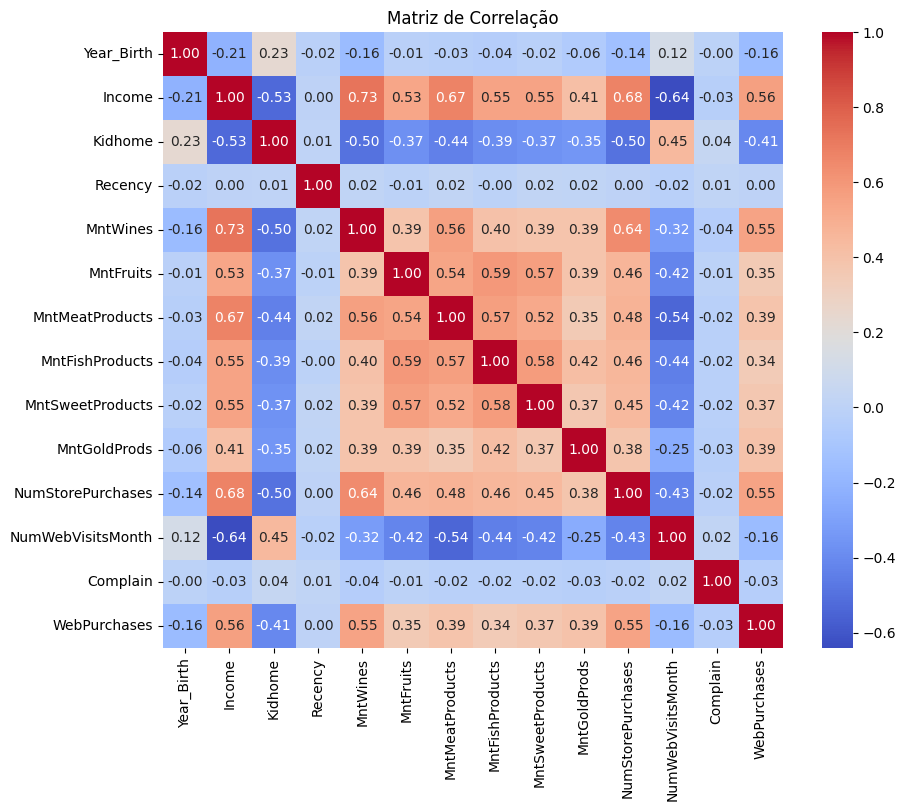

In [17]:
correlation_matrix = df.select_dtypes(include=['number']).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", annot_kws={"size": 10})
plt.title('Matriz de Correlação')
plt.show()

**Maiores Correlações com a Variável Target ('Web_Purchases'):**

- Web_Purchases x Income (0,56): clientes com maior renda tendem a realizar mais compras pela internet.

- Web_Purchases x MntWines (0,55): clientes que gastam mais com vinhos tendem a apresentar maior número de compras online.

- Web_Purchases x NumStorePurchases (0,55): clientes que compram mais em lojas físicas também tendem a comprar mais pela internet.

- Web_Purchases x Kidhome (-0,41): é a maior correlação negativa com a target. Mais crianças pequenas no domicílio estão associadas a menos compras online.

**Maiores Correlações entre as Variáveis:**

- Income × MntWines (0,73)

- Income × NumStorePurchases (0,68)

- Income × MntMeatProducts (0,67)

- MntWines × NumStorePurchases (0,64)

- MntFruits × MntSweetProducts (0,57)

- Income × NumWebVisitsMonth (-0,64)

- Income × Kidhome (-0,53)

- Kidhome × NumStorePurchases (-0,50)

- Kidhome × MntWines (-0,50)

- MntMeatProducts × NumWebVisitsMonth (-0,54)

### Codificação de Variáveis Categóricas (One-Hot Encoding):

In [47]:
df['Education'] = df['Education'].map({'Basic': 0, 'Graduation': 1, 'Master': 2, '2n Cycle': 3, 'PhD': 4})

In [48]:
df = pd.get_dummies(df, columns=['Marital_Status'], dtype=int)

A variável `Education` foi codificada por meio do método `map()`, atribuindo valores numéricos aos diferentes níveis de escolaridade: `Basic` (0), `Graduation` (1), `Master` (2), `2n Cycle` (3) e `PhD` (4). Essa abordagem preserva a ordem dos níveis educacionais, representando-os de forma ordinal.

Para a variável `Marital_Status`, foi utilizada a técnica `One-Hot Encoding`, por meio da função `pd.get_dummies()`. Esse procedimento transforma as categorias do estado civil em colunas binárias independentes, atribuindo o valor 1 quando o registro pertence à respectiva categoria e 0 caso contrário. 

Dessa forma, as duas abordagens foram escolhidas de acordo com a natureza das variáveis: a codificação ordinal para `Education`, que possui uma ordem natural entre os níveis de escolaridade, e a codificação `One-Hot Encoding` para `Marital_Status`, cujas categorias não possuem uma ordem definida entre si.

### Matriz de Correlação (com codificação das variáveis categóricas):

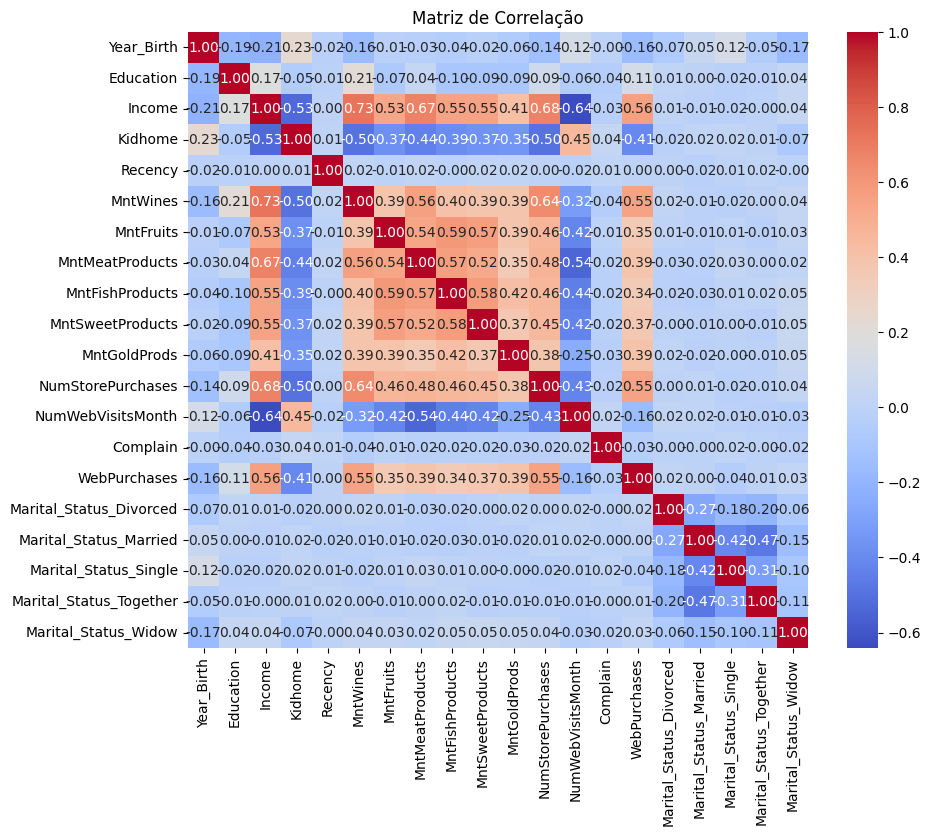

In [19]:
correlation_matrix = df.select_dtypes(include=['number']).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", annot_kws={"size": 10})
plt.title('Matriz de Correlação')
plt.show()

A codificação permitiu incluir `Education` e as categorias de `Marital_Status` na matriz de correlação. Porém, as variáveis categóricas adicionadas apresentam correlações fracas com a target (`Web_Purchases`), pricipalmente as relacionadas ao estado civil. Portanto, as principais variáveis associadas à target continuam sendo `Income`, `MntWines`, `NumStorePurchases` e `Kidhome`.

In [49]:
df.head()

,Year_Birth,Education,Income,Kidhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumStorePurchases,NumWebVisitsMonth,Complain,WebPurchases,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
0,1957,1,58138.0,0,58,635,88,546,172,88,88,4,7,0,1,0,0,1,0,0
1,1954,1,46344.0,1,38,11,1,6,2,1,6,2,5,0,0,0,0,1,0,0
2,1965,1,71613.0,0,26,426,49,127,111,21,42,10,4,0,1,0,0,0,1,0
3,1984,1,26646.0,1,26,11,4,20,10,3,5,4,6,0,0,0,0,0,1,0
4,1981,4,58293.0,1,94,173,43,118,46,27,15,6,5,0,1,0,1,0,0,0


In [ ]:
# df = df.drop(columns=['Marital_Status_Single', 'Complain', 'Marital_Status_Widow',
#                 'Marital_Status_Divorced', 'Marital_Status_Together', 
#                 'Marital_Status_Married', 'Recency'])

Inicialmente, optou-se por não remover as variáveis que apresentaram baixa correlação com a target `WebPurchases`, mantendo todas as características disponíveis para uma análise mais completa. A decisão de manter essas variáveis nesta etapa permite avaliar seu comportamento em conjunto com as demais características dos clientes, uma vez que algumas podem contribuir para a capacidade preditiva dos modelos mesmo quando apresentam baixa correlação individual com a variável target.

### Separação em Treino e Teste:

In [50]:
X = df.drop(columns=["WebPurchases"])
Y = df['WebPurchases']

In [52]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

### Balanceamento da Variável Target (com SMOTE):

In [55]:
smote = SMOTE(random_state=42)

In [56]:
X_train_balanced, Y_train_balanced = smote.fit_resample(X_train, Y_train)

In [57]:
counts = Y_train_balanced.value_counts()
print(counts)

WebPurchases
1    893
0    893
Name: count, dtype: int64


Após a aplicação do `SMOTE (Synthetic Minority Over-sampling Technique)`, que gera exemplos sintéticos da classe minoritária a partir das características dos dados existentes. As duas classes de `WebPurchases` ficaram equilibradas, com 893 registros para cada classe. Esse procedimento busca reduzir o viés dos modelos em favor da classe majoritária, contribuindo para uma melhor identificação de ambas as classes.

### Padronização das Variáveis (com StandardScaler): 

In [60]:
sc = StandardScaler()

In [61]:
X_train_scaled = sc.fit_transform(X_train_balanced)
X_test_scaled = sc.transform(X_test)

Foi aplicada a técnica de padronização utilizando o `StandardScaler`, com o objetivo de colocar as variáveis numéricas em uma escala comum, com média igual a zero e desvio padrão igual a um. Esse procedimento evita que variáveis com valores numericamente maiores tenham influência desproporcional no treinamento dos modelos. O método `fit_transform()` foi aplicado aos dados de treinamento balanceados, enquanto o método `transform()` foi utilizado nos dados de teste, utilizando os parâmetros calculados no treinamento. Dessa forma, evita-se o vazamento de informações dos dados de teste, garantindo uma avaliação mais confiável do desempenho dos modelos.

- `fit_transform()` aprende e transforma; 
- `transform()` apenas transforma com o que já foi aprendido.

In [64]:
print(X_train_scaled.shape)
print(Y_train_balanced.shape)
print(X_test_scaled.shape)
print(Y_test.shape)

(1786, 19)
(1786,)
(447, 19)
(447,)


In [85]:
pd.DataFrame(X_train_scaled).to_csv('X_train_scaled.csv', index=False)
pd.DataFrame(X_test_scaled).to_csv('X_test_scaled.csv', index=False)
pd.DataFrame(Y_train_balanced).to_csv('Y_train.csv', index=False)
pd.DataFrame(Y_test).to_csv('Y_test.csv', index=False)

**Obs: Salvei os dados em arquivos CSV para evitar a necessidade de executar todo o código novamente, considerando que o desenvolvimento foi realizado ao longo de vários dias.**

# ETAPA 3:

**Modelagem**

Escolha ao menos 2 técnicas de machine learning e rode 2 modelos, afim de identificar qual tem o melhor resultado para essa base. Lembrando que estamos lidando com uma classificação binária.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
X_train_scaled = pd.read_csv("X_train_scaled.csv")
X_test_scaled = pd.read_csv("X_test_scaled.csv")
Y_train = pd.read_csv("Y_train.csv")
Y_test = pd.read_csv("Y_test.csv")

In [66]:
X_train_scaled

array([[ 0.44564568,  0.79476366, -0.10112991, ..., -0.52508503,
         1.67816546, -0.18320703],
       [-0.49193785, -0.8037137 ,  0.7974751 , ..., -0.52508503,
        -0.5958888 , -0.18320703],
       [ 0.95705488,  0.79476366,  2.18218114, ..., -0.52508503,
        -0.5958888 , -0.18320703],
       ...,
       [ 0.61611541, -0.8037137 ,  1.64927218, ..., -0.52508503,
         1.67816546, -0.18320703],
       [-0.23623325, -0.8037137 ,  0.2954467 , ..., -0.52508503,
         1.67816546, -0.18320703],
       [ 1.72416867,  0.79476366, -0.63623071, ..., -0.52508503,
         1.67816546, -0.18320703]], shape=(1786, 19))

In [67]:
Y_train

1135    1
680     1
1995    1
1405    0
1381    0
       ..
1641    0
1098    0
1133    1
1297    1
863     1
Name: WebPurchases, Length: 1786, dtype: int64

In [68]:
X_test_scaled

array([[ 0.27517595, -0.00447502, -0.25923452, ...,  1.90445347,
        -0.5958888 , -0.18320703],
       [-0.06576352, -0.8037137 ,  0.46606914, ..., -0.52508503,
        -0.5958888 , -0.18320703],
       [-0.40670298,  1.59400233,  1.3189865 , ..., -0.52508503,
        -0.5958888 , -0.18320703],
       ...,
       [ 0.27517595, -0.8037137 ,  0.24235551, ..., -0.52508503,
        -0.5958888 , -0.18320703],
       [-1.34428651, -0.8037137 , -0.83573671, ..., -0.52508503,
         1.67816546, -0.18320703],
       [ 1.04228974, -0.00447502, -0.72020247, ..., -0.52508503,
        -0.5958888 , -0.18320703]], shape=(447, 19))

In [69]:
Y_test

1037    0
429     1
485     1
758     0
448     0
       ..
1115    0
1914    1
1214    1
2112    0
574     0
Name: WebPurchases, Length: 447, dtype: int64

### Regressão Logística:

In [4]:
modelo1 = LogisticRegression(random_state=42)

### Treino:

In [5]:
modelo1.fit(X_train_scaled, Y_train)

c:\Users\willi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [6]:
Y_pred_train1 = modelo1.predict(X_train_scaled)

In [7]:
report1 = classification_report(Y_train, Y_pred_train1)
print(f"Relatório de Previsões: \n{report1}")

Relatório de Previsões: 
              precision    recall  f1-score   support

           0       0.86      0.85      0.85       893
           1       0.85      0.86      0.86       893

    accuracy                           0.85      1786
   macro avg       0.86      0.85      0.85      1786
weighted avg       0.86      0.85      0.85      1786



Após o treinamento com os dados padronizados, o modelo alcançou uma `accuracy` de 85%, apresentando resultados equilibrados entre as duas classes. O `precision`, `recall` e `F1-score` ficaram entre 85% e 86%, indicando um desempenho consistente na classificação.

### Teste:

In [8]:
Y_pred_test1 = modelo1.predict(X_test_scaled)

In [9]:
report2 = classification_report(Y_test, Y_pred_test1)
print(f"Relatório de Classificação: \n{report2}")

Relatório de Classificação: 
              precision    recall  f1-score   support

           0       0.84      0.85      0.85       216
           1       0.86      0.85      0.85       231

    accuracy                           0.85       447
   macro avg       0.85      0.85      0.85       447
weighted avg       0.85      0.85      0.85       447



### Matriz de Confusão:

In [10]:
matriz1 = confusion_matrix(Y_test, Y_pred_test1)
print(f"Matriz de Confusão: \n{matriz1}")

Matriz de Confusão: 
[[183  33]
 [ 34 197]]


A matriz de Confusão mostra que o modelo apresentou desempenho semelhante em classificar ambas as classes, com uma diferença de um erro a menos para a classe 0.

### Curva ROC-AUC:

A Curva `ROC-AUC` é uma métrica utilizada para avaliar o desempenho de modelos de classificação. A curva `ROC` mostra a relação entre a taxa de verdadeiros positivos e a taxa de falsos positivos para diferentes limiares de classificação. Já a `AUC` representa a área sob essa curva, indicando a capacidade do modelo de distinguir entre as classes: quanto mais próximo de 1, melhor o desempenho discriminatório.

Nesse projeto são calculadas as probabilidades previstas pelo modelo para a classe positiva (`classe 1`) a partir dos dados de teste normalizados.

In [ ]:
# Probabilidade prevista para a classe 1
Y_prob_test1 = modelo1.predict_proba(X_test_scaled)[:, 1]

# Curva ROC e AUC
fpr, tpr, thresholds = roc_curve(Y_test, Y_prob_test1)

roc_auc = roc_auc_score(Y_test, Y_prob_test1)
print(f"AUC: {roc_auc:.2f}")

AUC: 0.90


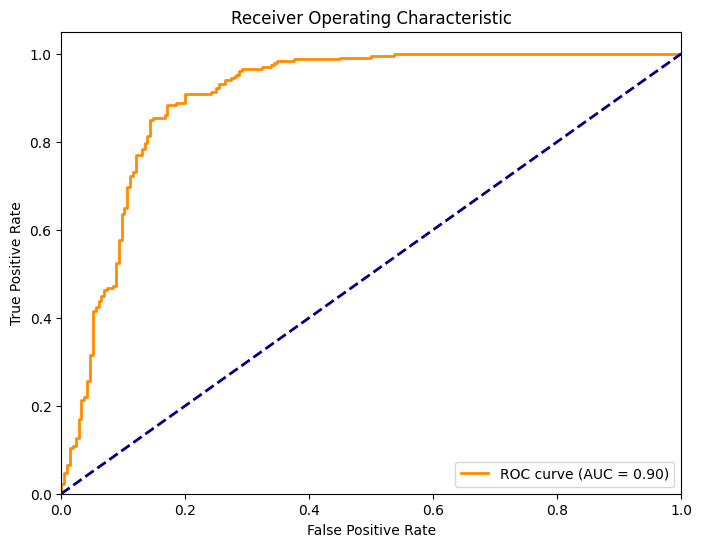

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

Comparando os resultados do treinamento com os dados de teste, a Regressão Logística apresentou um desempenho consistente. No treinamento, o modelo obteve 85% de `accuracy`, com `precision`, `recall` e `F1-score` entre 85% e 86%. Já nos dados de teste, manteve 85% de `accuracy`, com as três métricas em aproximadamente 85% para ambas as classes. A curva `ROC` também apresentou uma `AUC` de 0,90, indicando um bom desempenho. A pequena diferença entre os resultados de treinamento e teste sugere que o modelo conseguiu generalizar bem para dados não vistos, sem indícios evidentes de sobreajuste (overfitting).

### Regressão Logística com Melhora de Hiperparâmetrose e Cross Validation:

In [12]:
modelo2 = LogisticRegression(random_state=42, max_iter=1000)

In [13]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga']
    }

In [15]:
cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [15]:
grid_search = GridSearchCV(modelo2, param_grid, cv=cross_validation, scoring='accuracy', n_jobs=-1)

### Treino:

In [16]:
grid_search.fit(X_train_scaled, Y_train)

c:\Users\willi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\willi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 0.1, ...], 'penalty': ['l1', 'l2'], 'solver': ['liblinear', 'saga']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candid

In [17]:
best_params = grid_search.best_params_
print(f"Melhores Parâmetros: {best_params}")

Melhores Parâmetros: {'C': 1, 'penalty': 'l2', 'solver': 'liblinear'}


In [18]:
best_model = grid_search.best_estimator_

In [19]:
Y_pred_train2 = best_model.predict(X_train_scaled)

In [20]:
report3 = classification_report(Y_train, Y_pred_train2)
print(f"Relatório de Classificação: \n{report3}")

Relatório de Classificação: 
              precision    recall  f1-score   support

           0       0.86      0.85      0.85       893
           1       0.85      0.86      0.85       893

    accuracy                           0.85      1786
   macro avg       0.85      0.85      0.85      1786
weighted avg       0.85      0.85      0.85      1786



A `acurácia` do modelo no conjunto de treino foi de 85%. Com `recall` de 85% para a classe 0 e 86% para a classe 1. E `F1-score` de 85% para ambas as classes. De forma geral, o modelo apresenta um desempenho satisfatório no treino, com métricas equilibradas entre as duas classes.

### Avaliação Validação Cruzada:

In [25]:
cv_scores = cross_val_score(
    best_model,
    X_train_scaled,
    Y_train,
    cv=cross_validation,
    scoring="accuracy",
    n_jobs=-1
)

print(f"Scores cross validation: {cv_scores}")
print(f"Acurácia média: {np.mean(cv_scores):.2f}")
print(f"Desvio padrão: {np.std(cv_scores):.2f}")

Scores cross validation: [0.82681564 0.84593838 0.87394958 0.85434174 0.83193277]
Acurácia média: 0.85
Desvio padrão: 0.02


- Scores: 0.82681564; 0.84593838; 0.87394958; 0.85434174; 0.83193277.

- Acurácia média: 0.85 (85%).

- Desvio padrão: 0.02 (2 pontos percentuais).

A acurácia média de 85% indica o desempenho médio obtido nas cinco divisões da validação cruzada. Já o desvio padrão de 2 pontos percentuais mostra que existe uma pequena variação entre os resultados, embora o desempenho geral permaneça em uma faixa semelhante.

### Teste:

In [21]:
Y_pred_test2 = best_model.predict(X_test_scaled)

In [22]:
report4 = classification_report(Y_test, Y_pred_test2)
print(f"Relatório de Classificação: \n{report4}")

Relatório de Classificação: 
              precision    recall  f1-score   support

           0       0.84      0.85      0.85       216
           1       0.86      0.85      0.85       231

    accuracy                           0.85       447
   macro avg       0.85      0.85      0.85       447
weighted avg       0.85      0.85      0.85       447



### Matriz de Confusão:

In [23]:
matriz2 = confusion_matrix(Y_test, Y_pred_test2)
print(f"Matriz de Confusão: \n{matriz2}")

Matriz de Confusão: 
[[183  33]
 [ 34 197]]


A matriz de Confusão mostra que o modelo apresentou desempenho semelhante em classificar ambas as classes, com uma diferença de um erro a menos para a classe 0.

### Curva ROC-AUC:

In [ ]:
# Probabilidade prevista para a classe 1
Y_pred_test2 = best_model.predict_proba(X_test_scaled)[:, 1]

# Curva ROC e AUC
fpr, tpr, thresholds = roc_curve(Y_test, Y_pred_test2)

roc_auc = roc_auc_score(Y_test, Y_pred_test2)
print(f"AUC: {roc_auc:.2f}")

AUC: 0.90


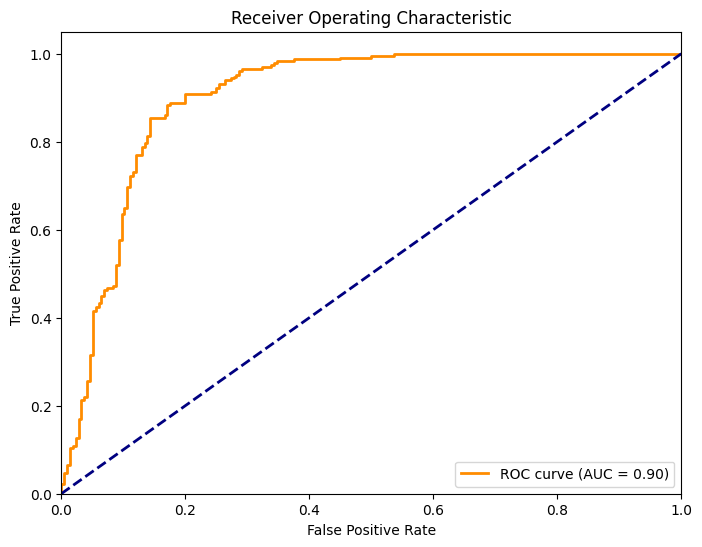

In [24]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

No conjunto de teste, a `accuracy` foi de 85%, com `recall` de 85% para ambas as classes. E com `F1-score` de 85% para ambas as classes. A curva `ROC` também apresentou uma `AUC` de 0,90 em ambos os casos (com e sem ajustes de hiperparâmetros). Os resultados indicam que o modelo mantém um desempenho equilibrado em dados não vistos durante o treinamento. 

### Comparação entre os Modelos (Regressão Logística):

A comparação entre a `Regressão Logística` sem ajuste e com ajuste de hiperparâmetros mostrou que não houve melhora significativa no desempenho do modelo. Em ambas as versões, a `accuracy` permaneceu em 85% tanto nos dados de treinamento quanto nos de teste. As métricas de `precision`, `recall` e `F1-score` também apresentaram valores praticamente idênticos. E a curva `ROC` também apresentou uma `AUC` de 0,90 em ambos os casos, sugerindo um bom desempenho para a classe positiva `classe 1`.

Mesmo com a aplicação do `GridSearchCV`, utilizando validação cruzada estratificada com cinco divisões `(StratifiedKFold)`, a busca pelos melhores hiperparâmetros não resultou em ganhos perceptíveis nas métricas avaliadas. A validação cruzada apresentou `accuracy` média de 85% e desvio padrão de 0,02, indicando resultados relativamente consistentes entre as divisões. Portanto, os ajustes não trouxeram benefícios aparentes em relação ao modelo original, que já apresentava um desempenho estável e uma boa capacidade de generalização. Isso não significa que a otimização foi inútil, mas que, para esse conjunto de dados e essas métricas, a configuração padrão já apresentou resultados semelhantes.

### RandomForest:

In [4]:
modelo3 = RandomForestClassifier(random_state=42)

### Treino:

In [22]:
modelo3.fit(X_train_scaled, Y_train)

c:\Users\willi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [23]:
Y_pred_train3 = modelo3.predict(X_train_scaled)

In [24]:
report5 = classification_report(Y_train, Y_pred_train3)
print(f"Relatório de Classificação: \n{report5}")

Relatório de Classificação: 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       893
           1       1.00      1.00      1.00       893

    accuracy                           1.00      1786
   macro avg       1.00      1.00      1.00      1786
weighted avg       1.00      1.00      1.00      1786



O modelo `Random Forest`, utilizando os hiperparâmetros padrão, alcançou 100% de `accuracy` nos dados de treinamento, apresentando `precision`, `recall` e `F1-score` de 1,00 para ambas as classes. Esse resultado demonstra que o modelo conseguiu classificar corretamente todos os registros utilizados durante o treinamento.

### Teste:

In [25]:
Y_pred_test3 = modelo3.predict(X_test_scaled)

In [26]:
report6 = classification_report(Y_test, Y_pred_test3)
print(f"Relatório de Classificação: \n{report6}")

Relatório de Classificação: 
              precision    recall  f1-score   support

           0       0.94      0.88      0.91       216
           1       0.90      0.94      0.92       231

    accuracy                           0.91       447
   macro avg       0.92      0.91      0.91       447
weighted avg       0.92      0.91      0.91       447



### Matriz de Confusão:

In [27]:
matriz3 = confusion_matrix(Y_test, Y_pred_test3)
print(f"Matriz de Confusão: \n{matriz3}")

Matriz de Confusão: 
[[191  25]
 [ 13 218]]


A matriz de Confusão mostra que o modelo apresentou melhor desempenho em classificar a classe 1, com apenas 13 erros e dificuldade em classicar a classe 0 com 25 erros.

### Curva ROC-AUC:

In [ ]:
# Probabilidade prevista para a classe 1
Y_pred_test3 = modelo3.predict_proba(X_test_scaled)[:, 1]

# Curva ROC e AUC
fpr, tpr, thresholds = roc_curve(Y_test, Y_pred_test3)

roc_auc = roc_auc_score(Y_test, Y_pred_test3)
print(f"AUC: {roc_auc:.2f}")

AUC: 0.97


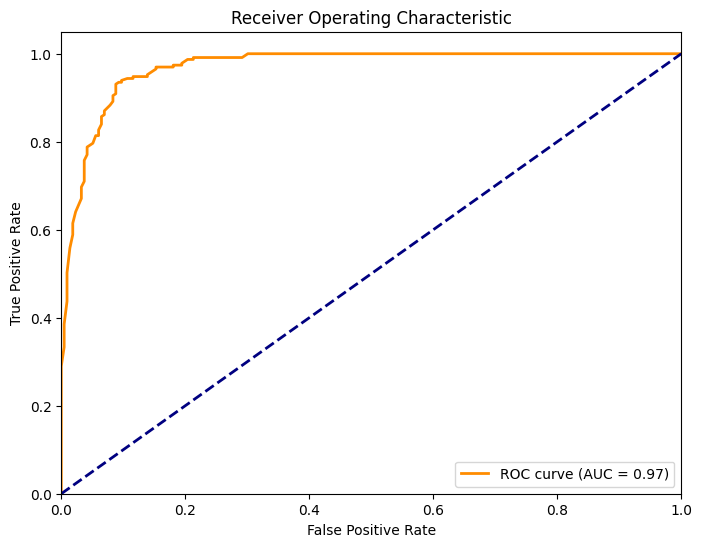

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

Nos dados de teste, a `accuracy` foi de 91%, com `F1-score` de 0,91 para a classe 0 e 0,92 para a classe 1, e `recall` de 0,88 para classe 0 e 0,94 para classe 1. A curva `ROC` também apresentou uma `AUC` de 0,97. A diferença entre o desempenho no treinamento e no teste sugere um possível sobreajuste (overfitting), indicando que o modelo pode ter memorizado características dos dados de treinamento e apresentar menor capacidade de generalização para novos registros.

### RandomForest com Melhora de Hiperparâmetrose e Cross Validation:

In [5]:
param_grid = {
    'n_estimators': randint(50, 200),
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': randint(2, 10),
    'min_samples_leaf': randint(1, 6),
    'max_features': ['sqrt', 'log2', None]
}

In [6]:
random_search = RandomizedSearchCV(modelo3, param_grid, n_iter=100, cv=5, scoring='accuracy', n_jobs=-1, random_state=42)

### Treino:

In [7]:
random_search.fit(X_train_scaled, Y_train)

c:\Users\willi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2', ...], 'min_samples_leaf': <scipy.stats....001ECBCB0B250>, 'min_samples_split': <scipy.stats....001ECBCB0AFD0>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",100
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the various

In [8]:
best_params = random_search.best_params_
print(f"Melhores Hiperparâmetros: {best_params}")

Melhores Hiperparâmetros: {'max_depth': 20, 'max_features': None, 'min_samples_leaf': 4, 'min_samples_split': 9, 'n_estimators': 103}


In [9]:
best_random_forest = random_search.best_estimator_
best_random_forest.fit(X_train_scaled, Y_train)

c:\Users\willi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",103
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",9
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_t

In [10]:
Y_pred_train4 = best_random_forest.predict(X_train_scaled)

In [13]:
report7 = classification_report(Y_train, Y_pred_train4)
print(f"Relatório de Classificação: \n{report7}")

Relatório de Classificação: 
              precision    recall  f1-score   support

           0       0.98      0.94      0.96       893
           1       0.95      0.98      0.96       893

    accuracy                           0.96      1786
   macro avg       0.96      0.96      0.96      1786
weighted avg       0.96      0.96      0.96      1786



Após a otimização dos hiperparâmetros com `RandomizedSearchCV`, o modelo apresentou 96% de `accuracy` nos dados de treinamento, com `recall` de 0,94 para a classe 0 e 0,98 para a classe 1. O `F1-score` foi de 0,96 para ambas as classes, indicando um bom equilíbrio entre precisão e capacidade de identificação dos registros positivos.

### Avaliação Validação Cruzada:

In [16]:
cv_scores = cross_val_score(
    best_random_forest,
    X_train_scaled,
    Y_train,
    cv=cross_validation,
    scoring="accuracy",
    n_jobs=-1
)

print(f"Scores cross validation: {cv_scores}")
print(f"Acurácia média: {np.mean(cv_scores):.2f}")
print(f"Desvio padrão: {np.std(cv_scores):.2f}")

Scores cross validation: [0.91340782 0.90756303 0.92436975 0.88795518 0.88235294]
Acurácia média: 0.90
Desvio padrão: 0.02


- Scores: 0.91340782; 0.90756303; 0.92436975; 0.88795518; 0.88235294.

- Acurácia média: 0.90 (90%).

- Desvio padrão: 0.02 (2 pontos percentuais).

A acurácia média de 90% indica o bom desempenho médio obtido nas cinco divisões da validação cruzada. Já o desvio padrão de 2 pontos percentuais mostra que existe uma pequena variação entre os resultados, embora o desempenho geral permaneça em uma faixa semelhante.

### Teste:

In [17]:
Y_pred_test4 = best_random_forest.predict(X_test_scaled)

In [18]:
report8 = classification_report(Y_test, Y_pred_test4)
print(f"Relatório de Classificação: \n{report8}")

Relatório de Classificação: 
              precision    recall  f1-score   support

           0       0.92      0.89      0.91       216
           1       0.90      0.93      0.91       231

    accuracy                           0.91       447
   macro avg       0.91      0.91      0.91       447
weighted avg       0.91      0.91      0.91       447



### Matriz de Confusão:

In [19]:
matriz4 = confusion_matrix(Y_test, Y_pred_test4)
print(f"Matriz de Confusão: \n{matriz4}")

Matriz de Confusão: 
[[193  23]
 [ 17 214]]


A matriz de Confusão mostra que o modelo apresentou melhor desempenho em classificar a classe 1, com apenas 17 erros e dificuldade em classificar a classe 0 com 23 erros. Porém, comparado ao modelo anterior, a classe 1 aumentou em 4 o número de erros, enquanto a classe 0 diminuiu em 2.

### Curva ROC-AUC:

In [ ]:
# Probabilidade prevista para a classe 1
Y_pred_test4 = best_random_forest.predict_proba(X_test_scaled)[:, 1]

# Curva ROC e AUC
fpr, tpr, thresholds = roc_curve(Y_test, Y_pred_test4)

roc_auc = roc_auc_score(Y_test, Y_pred_test4)
print(f"AUC: {roc_auc:.2f}")

AUC: 0.97


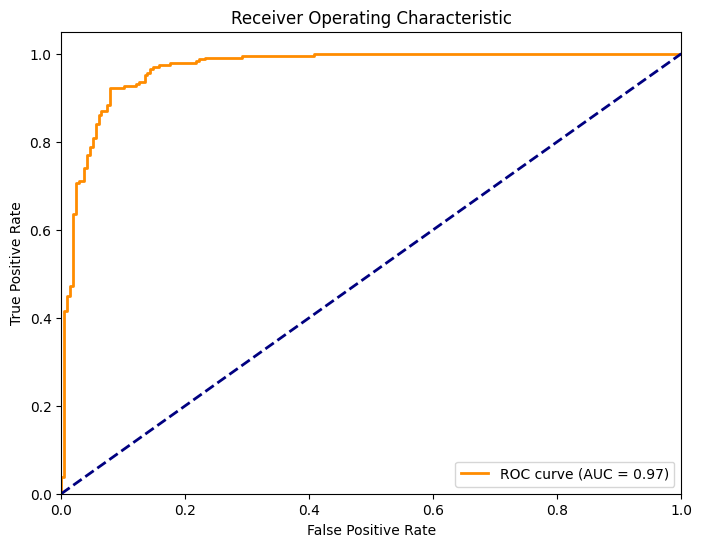

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

Nos dados de teste, a `accuracy` permaneceu em 91%, com `recall` de 0,89 para a classe 0 e 0,93 para a classe 1 e com `F1-score` de 0,91 para as duas classes. A curva `ROC` também apresentou uma `AUC` de 0,97 em ambos os casos. A matriz de confusão registrou 407 previsões corretas e 40 incorretas, sendo 193 acertos da classe 0 e 214 da classe 1. A redução da `accuracy` no treinamento, de 100% para 96%, sem perda significativa no teste, sugere que o ajuste ajudou a reduzir o sobreajuste, mantendo um bom desempenho em dados não utilizados durante o treinamento.

### Comparação entre os Modelos (RandomForest):

A comparação demonstra que o ajuste de hiperparâmetros reduziu a `accuracy` do treinamento de 100% para 96%, indicando uma redução do possível sobreajuste (overfitting). Nos dados de teste, a `accuracy` permaneceu em 91% nos dois modelos, mas houve pequenas diferenças no `recall` para a classe 0, aumentou de 88% para 89%, enquanto para a classe 1 diminuiu de 94% para 93%. Por outro lado, o modelo sem ajuste apresentou dois acertos a mais no teste, além de um `F1-score` ligeiramente superior para a classe 1. E a curva `ROC` também apresentou uma `AUC` de 0,97 em ambos os casos, sugerindo um excelente desempenho para a classe positiva `classe 1`.

Portanto, os dois modelos apresentaram desempenho semelhante em dados novos, mas o modelo ajustado alcançou um resultado de treinamento menos perfeito e potencialmente mais equilibrado. Ou seja, a otimização tornou o modelo menos ajustado aos dados de treinamento sem alterar sua capacidade preditiva no conjunto de teste.

### Importância das variáveis para o modelo:

In [70]:
# Importância das variáveis
df_importancias = pd.DataFrame({"Variável": X_train.columns, "Importância": modelo3.feature_importances_})

# Ordena da maior para a menor importância
df_importancias = df_importancias.sort_values(by="Importância", ascending=False)

display(df_importancias)

,Variável,Importância
5,MntWines,0.255384
7,MntMeatProducts,0.175440
11,NumStorePurchases,0.118568
2,Income,0.086569
12,NumWebVisitsMonth,0.070988
10,MntGoldProds,0.058383
6,MntFruits,0.049882
9,MntSweetProducts,0.043784
8,MntFishProducts,0.042325
0,Year_Birth,0.030435


### Conclusão para o marketing:

| Variável | Insight exploratório |	Possível aplicação no marketing |
|---|---:|---:|
| MntWines | Correlação positiva com compras online | Testar campanhas segmentadas de vinhos para clientes com maior afinidade com essa categoria |
| MntMeatProducts |	Correlação positiva com compras online | Testar ofertas personalizadas de carnes e produtos relacionados para clientes com maior consumo nessa categoria |
| NumStorePurchases | Correlação positiva com compras online | Testar ações que integrem compras físicas e digitais, como cupons online para clientes da loja física |
| Income | Correlação positiva com compras online | Avaliar segmentações por faixa de renda e testar ofertas adequadas ao perfil de consumo |
| NumWebVisitsMonth	| Correlação negativa com compras online | Analisar clientes que visitam o site com frequência e testar melhorias na navegação, recomendações e incentivos à conversão |

A análise exploratória dos dados, em conjunto com o modelo `Random Forest ajustado`, permite identificar características dos clientes que ajudam a prever a probabilidade de realizar compras pela internet `WebPurchases`. Entre as variáveis de maior importância para o modelo, destacam-se os gastos com vinhos `MntWines`, os gastos com carnes `MntMeatProducts`, o número de compras em lojas físicas `NumStorePurchases` e a renda `Income`.

Esses resultados sugerem oportunidades para desenvolver campanhas de marketing mais segmentadas. Clientes que apresentam maior consumo de determinados produtos podem receber ofertas personalizadas, enquanto o histórico de compras em lojas físicas pode ajudar a identificar consumidores para campanhas que incentivem a migração ou ampliação das compras para o canal online. A renda e os gastos com outras categorias também podem contribuir para a criação de segmentos com ofertas mais adequadas ao perfil de consumo.

Outra oportunidade é investigar a relação entre o número de visitas ao site `NumWebVisitsMonth` e as compras online. Essa variável pode ajudar a identificar clientes que acessam o site, mas não necessariamente concluem uma compra, permitindo testar ações como recomendações personalizadas, promoções e melhorias na experiência de compra.

# ETAPA 4:

**Avaliação**

Avalie os resultados encontrados nos dois modelos e identifique qual te pareceu realizar melhor as previsões.

Utilize além das métricas padrões a matriz de confusão.

### Comparação dos Resultados (Tabela):

| Métrica | Regressão Logística sem ajuste | Regressão Logística ajustada | Random Forest sem ajuste | Random Forest ajustado |
|---|---:|---:|---:|---:|
| Acurácia — treino | 85% | 85% | 100% | 96% |
| Acurácia — teste | 85% | 85% | 91% | 91% |
| Recall — classe 0 (teste) | 85% | 85% | 88% | 89% |
| Recall — classe 1 (teste) | 85% | 85% | 94% | 93% |
| F1-score — classe 0 (teste) | 0,85 | 0,85 | 0,91 | 0,91 |
| F1-score — classe 1 (teste) | 0,85 | 0,85 | 0,92 | 0,91 |
| AUC (classe 1 - positivos) | 0,90 | 0,90 | 0,97 | 0,97 |
| Matriz de Confusão - teste - erros classe 0 | 33 | 33 | 25 | 23 |
| Matriz de Confusão - teste - erros classe 1 | 34 | 34 | 13 | 17 |
| Cross Validation - Acurácia | NaN | 85% | NaN | 90% |
| Cross Validation - Desvio Padrão | NaN | 0,02 | NaN | 0,02 |

### Análise dos Modelos:

**Regressão Logística sem ajuste:** apresentou 85% de `accuracy` tanto no treinamento quanto no teste. O desempenho equilibrado entre as classes indica uma boa consistência, mas os resultados sugerem uma capacidade de classificação inferior à do Random Forest.

**Regressão Logística ajustada:** mesmo após a aplicação do `GridSearchCV` e da validação cruzada estratificada, os resultados permaneceram praticamente idênticos aos do modelo original. Portanto, a otimização dos hiperparâmetros não proporcionou ganhos relevantes nas métricas avaliadas.

**Random Forest sem ajuste:** obteve 100% de `accuracy` no treinamento e 91% no teste. Embora tenha apresentado o maior `recall` para a classe 1 (94%), a diferença entre treinamento e teste sugere possível sobreajuste. Apesar disso, seu desempenho nos dados de teste foi superior ao da Regressão Logística.

**Random Forest ajustado:** alcançou 96% de `accuracy` no treinamento e 91% no teste. O ajuste reduziu a diferença entre os resultados de treinamento e teste, mantendo a `accuracy` e o `F1-score` praticamente iguais aos do modelo original. Também apresentou o maior `recall` para a classe 0 (89%), enquanto o `recall` da classe 1 foi de 93%.

### Melhor Modelo - Random Forest ajustado:

Considerando o desempenho e a diferença entre treinamento e teste, o `Random Forest ajustado` é a escolha mais equilibrada. Ele manteve 91% de `accuracy`, e reduziu a acurácia de treinamento de 100% para 96%, apresentou `recall` de 89% para a classe 0 e 93% para a classe 1 e `F1-score` de 0,91 para ambas as classes. A curva `ROC` também apresentou um aumento na `AUC` de 0,97 em comparação aos 0,90 da Regressão Logística.

É importante destacar que o `Random Forest sem ajuste` também obteve 91% de `accuracy`, com `recall` ligeiramente maior para a classe 1 e os mesmos 0,97 de `AUC`. Portanto, não houve superioridade absoluta do modelo ajustado em todas as métricas. A preferência pelo modelo ajustado se deve principalmente ao **menor indício de sobreajuste**, sem perda de acurácia no teste.

### Conclusão Final:

Os códigos demonstraram que o `Random Forest` apresentou desempenho superior à `Regressão Logística`, com aumento da `accuracy` nos dados de teste de 85% para 91%. Os ajustes de hiperparâmetros na `Regressão Logística` não produziram melhorias significativas, enquanto a otimização do `Random Forest` reduziu a diferença entre o desempenho no treinamento e no teste, mantendo a capacidade preditiva. E com base na `validação cruzada`, o `Random Forest ajustado` apresentou o melhor desempenho entre os dois modelos, alcançando `accuracy` média de 90%, contra 85% da `Regressão Logística ajustada`. Esse resultado reforça sua escolha como melhor modelo para o problema.

Dessa forma, o `Random Forest ajustado` foi selecionado como o **melhor modelo para este projeto**, por oferecer um bom equilíbrio entre desempenho e capacidade de generalização para dados novos.